# Card fraud triage
**Team T085 · Section E · Project 26 · Phase 2**

Can reconstruction error prioritize fraud better than the Phase 1 Gaussian mixture model (GMM) under the same review constraints? We compare frozen GMM negative log-density and autoencoder reconstruction MSE on chronological ULB/Kaggle partitions. High scores rank first for both models.

**Holdout status.** Phase 1 had already inspected the test partition. The comparison is historical. The new ablations use legitimate training and mixed validation only. An untouched later batch with compatible PCA features is still needed for a confirmatory evaluation.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "run_phase2_study.py").is_file())
study = root / "results/phase2/study"
metadata = json.loads((study / "metadata.json").read_text())
split_manifest = json.loads((root / "data/processed/split_manifest.json").read_text())
splits = pd.DataFrame(split_manifest["splits"])
display(splits[["split", "rows", "legitimate", "fraud", "base_rate"]].round(6))

,split,rows,legitimate,fraud,base_rate
0,train,170888,170528,360,0.002107
1,validation,56958,56901,57,0.001001
2,test,56961,56886,75,0.001317


## Frozen model and scoring protocol
Both pipelines start from the same 170,528 legitimate rows and use the same chronological validation and historical-test membership. Inputs are V1–V28 and `log1p(Amount)`. Time determines the chronology. Class identifies legitimate training rows and provides evaluation labels.

The Phase 1 GMM fits 20 full-covariance components chosen by training BIC. The original autoencoder has 16, 8 and 16 hidden units. ReLU enables nonlinear reconstruction, the eight-unit bottleneck compresses the input and the linear output can reconstruct signed standardized features. The original run fit noisy inputs (Gaussian standard deviation 0.05) to clean targets using Adam and reached its 35-epoch cap. Its internal random legitimate reserve monitored scikit-learn validation R². The anomaly score averages squared reconstruction error over all 29 clean features.

## Precision–recall and ranking metrics
Each panel uses its own fraud prevalence as the reference line. AP summarizes precision at recall increments. The trapezoidal PR area uses linear interpolation.

,model,split,average_precision,pr_auc_trapezoidal,roc_auc,base_rate
0,GMM,validation,0.629867,0.628444,0.940519,0.001001
1,GMM,test,0.582203,0.578669,0.918662,0.001317
2,Autoencoder,validation,0.037972,0.036845,0.942111,0.001001
3,Autoencoder,test,0.090755,0.088488,0.931869,0.001317


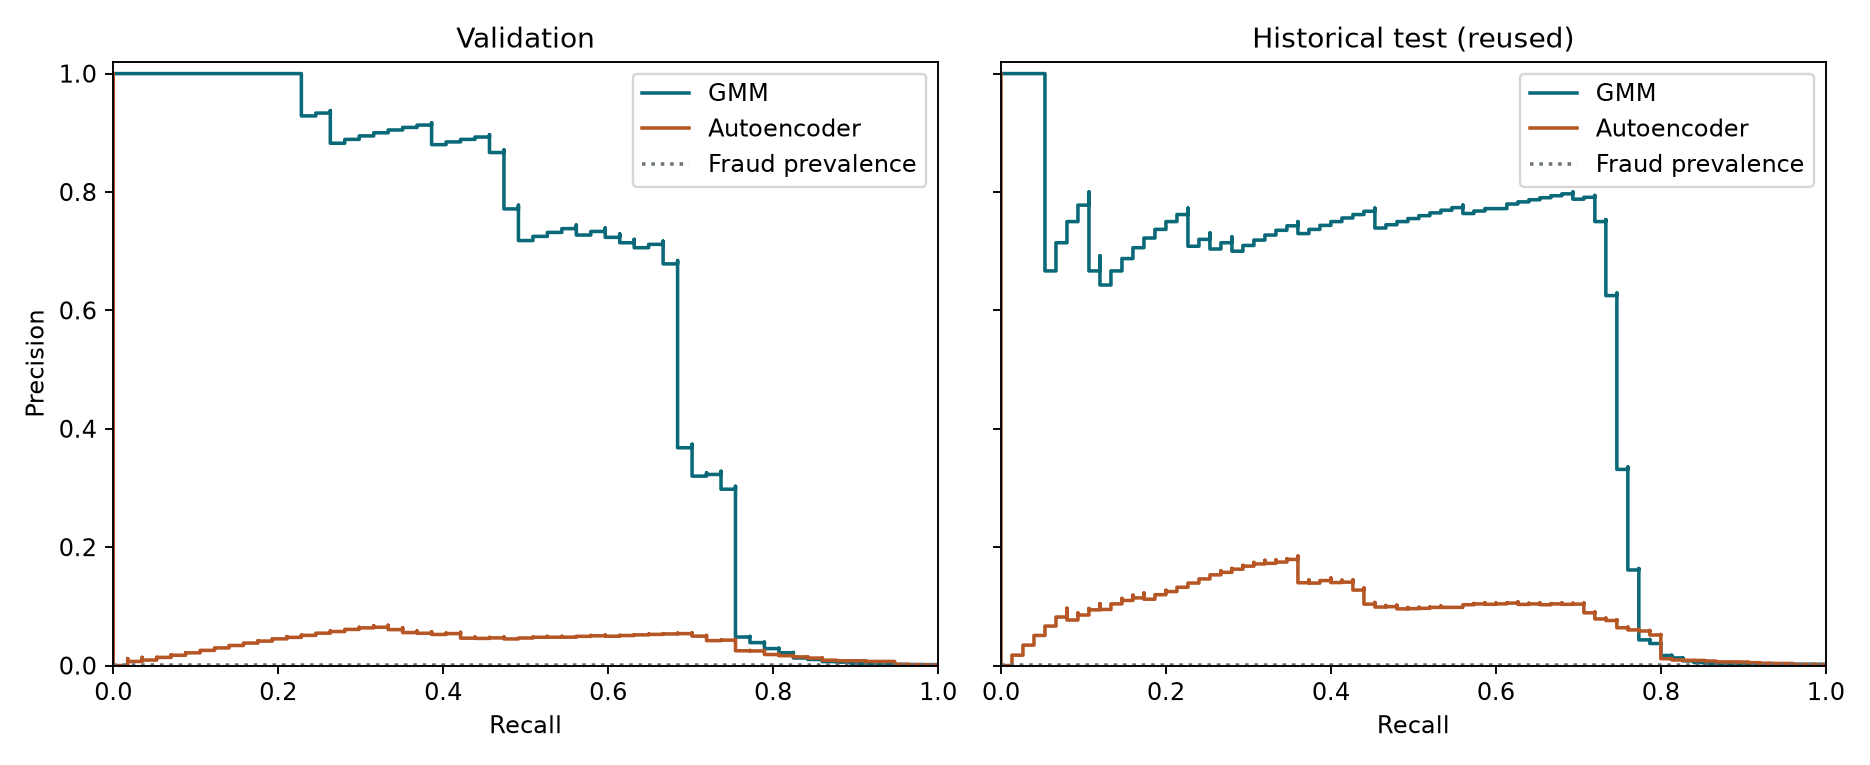

In [2]:
from math import isclose
from sklearn.metrics import auc

ranking = pd.read_csv(study / "ranking.csv")
coordinates = pd.read_csv(study / "precision_recall_points.csv.gz")
for row in ranking.itertuples(index=False):
    curve = coordinates[(coordinates.model == row.model) & (coordinates.split == row.split)]
    assert isclose(auc(curve.recall, curve.precision), row.pr_auc_trapezoidal, rel_tol=1e-10)

display(ranking.round(6))
display(Image(filename=str(study / "precision_recall.png"), width=940))

## False-positive budgets
For each model and budget, use the descending legitimate validation score at rank `floor(budget × legitimate_count)` with zero-based indexing. Send scores strictly above that cutoff to review. Freeze these cutoffs and measure resulting historical test FPR, recall, precision and alert workload.

In [3]:
points = pd.read_csv(study / "operating_points.csv")
historical = points.query("split == 'test'").copy()
for name in ("fpr_budget", "fpr", "recall", "precision"):
    historical[name] *= 100
display(historical[["model", "fpr_budget", "tp", "fp", "fn", "flagged", "fpr", "recall", "precision"]]
        .rename(columns={"fpr_budget": "Validation FPR budget (%)", "tp": "Frauds caught",
                         "fp": "False alerts", "fn": "Missed frauds", "flagged": "All alerts",
                         "fpr": "Realized test FPR (%)", "recall": "Recall (%)",
                         "precision": "Precision (%)"})
        .sort_values(["Validation FPR budget (%)", "model"]).round(3).reset_index(drop=True))

,model,Validation FPR budget (%),Frauds caught,False alerts,Missed frauds,All alerts,Realized test FPR (%),Recall (%),Precision (%)
0,Autoencoder,0.1,0,26,75,26,0.046,0.000,0.000
1,GMM,0.1,55,29,20,84,0.051,73.333,65.476
2,Autoencoder,0.5,27,135,48,162,0.237,36.000,16.667
3,GMM,0.5,57,175,18,232,0.308,76.000,24.569
4,Autoencoder,1.0,35,314,40,349,0.552,46.667,10.029
5,GMM,1.0,58,324,17,382,0.570,77.333,15.183
6,Autoencoder,5.0,60,2169,15,2229,3.813,80.000,2.692
7,GMM,5.0,60,2082,15,2142,3.660,80.000,2.801


At the 0.5% validation budget, the GMM finds 57 frauds with 175 false alerts. The autoencoder finds 27 with 135 false alerts. At 5% both catch 60 frauds, with more than 2,000 false alerts for each model. The differences between nominal and realized FPR show how a fixed threshold can translate into a different workload on later transactions.

## Equal review capacity
Rank each batch and take the top scores with ties broken by chronological row order. Queue lengths are the same for both models in a split.

In [4]:
capacity = pd.read_csv(study / "capacity.csv").query("split == 'test'").copy()
capacity["queue"] = capacity.apply(
    lambda row: f"Top {row.capacity_fraction:.1%}" if row.policy == "fraction" else "Top 100", axis=1)
capacity["precision_at_k"] *= 100
capacity["recall_at_k"] *= 100
display(capacity[["queue", "model", "k", "tp", "precision_at_k", "recall_at_k"]]
        .rename(columns={"k": "Reviews", "tp": "Frauds caught", "precision_at_k": "Precision (%)",
                         "recall_at_k": "Recall (%)"})
        .sort_values(["Reviews", "model"]).round(2).reset_index(drop=True))

,queue,model,Reviews,Frauds caught,Precision (%),Recall (%)
0,Top 0.1%,Autoencoder,56,0,0.00,0.00
1,Top 0.1%,GMM,56,43,76.79,57.33
2,Top 100,Autoencoder,100,11,11.00,14.67
3,Top 100,GMM,100,56,56.00,74.67
4,Top 0.5%,Autoencoder,284,33,11.62,44.00
5,Top 0.5%,GMM,284,57,20.07,76.00
6,Top 1.0%,Autoencoder,569,53,9.31,70.67
7,Top 1.0%,GMM,569,58,10.19,77.33


At 284 reviews, the GMM finds 57 frauds (20.07% precision) and the autoencoder finds 33 (11.62%). The frozen GMM leads this historical comparison on AP and at the specified review capacities.

## Validation-only autoencoder ablations
Change input noise at width 8 and change width at a fixed noise standard deviation of 0.05. Pair seeds across variants. A shared chronological reserve of legitimate observations selects checkpoints by clean reconstruction MSE. The scaler fits on the earlier legitimate rows. Training uses fresh Gaussian corruption each epoch for denoising, the same Adam settings for every variant, and a 35-epoch cap with patience of five epochs. The ablation study's mixed validation rows measure fraud ranking after checkpoint selection.

Weight/scaler fitting: 153,474 legitimate rows
Checkpoint reserve: 17,054 legitimate rows
Paired seeds: 13, 26, 42


,variant,width,noise_std,runs,mean_ap,sd_ap,mean_pr_auc,mean_recall,mean_precision
0,"Denoising, width 8",8,0.05,3,0.0497,0.0082,0.0484,0.4152,0.0769
1,"Clean, width 8",8,0.00,3,0.0507,0.0090,0.0493,0.4269,0.0789
2,"Denoising, width 4",4,0.05,3,0.0491,0.0050,0.0477,0.4035,0.0749
3,"Denoising, width 16",16,0.05,3,0.0606,0.0050,0.0589,0.4678,0.0858


,variant,seed,epochs,best_epoch,best_reserve_mse,average_precision
0,"Denoising, width 8",13,35,34,0.6421,0.0522
1,"Denoising, width 8",26,30,25,0.6446,0.0406
2,"Denoising, width 8",42,35,35,0.6236,0.0564
3,"Clean, width 8",13,35,34,0.6425,0.0535
4,"Clean, width 8",26,35,34,0.6684,0.0406
5,"Clean, width 8",42,35,35,0.6214,0.0579
6,"Denoising, width 4",13,35,34,0.7469,0.0433
7,"Denoising, width 4",26,35,35,0.7523,0.0526
8,"Denoising, width 4",42,35,35,0.7334,0.0514
9,"Denoising, width 16",13,12,7,0.5245,0.0662


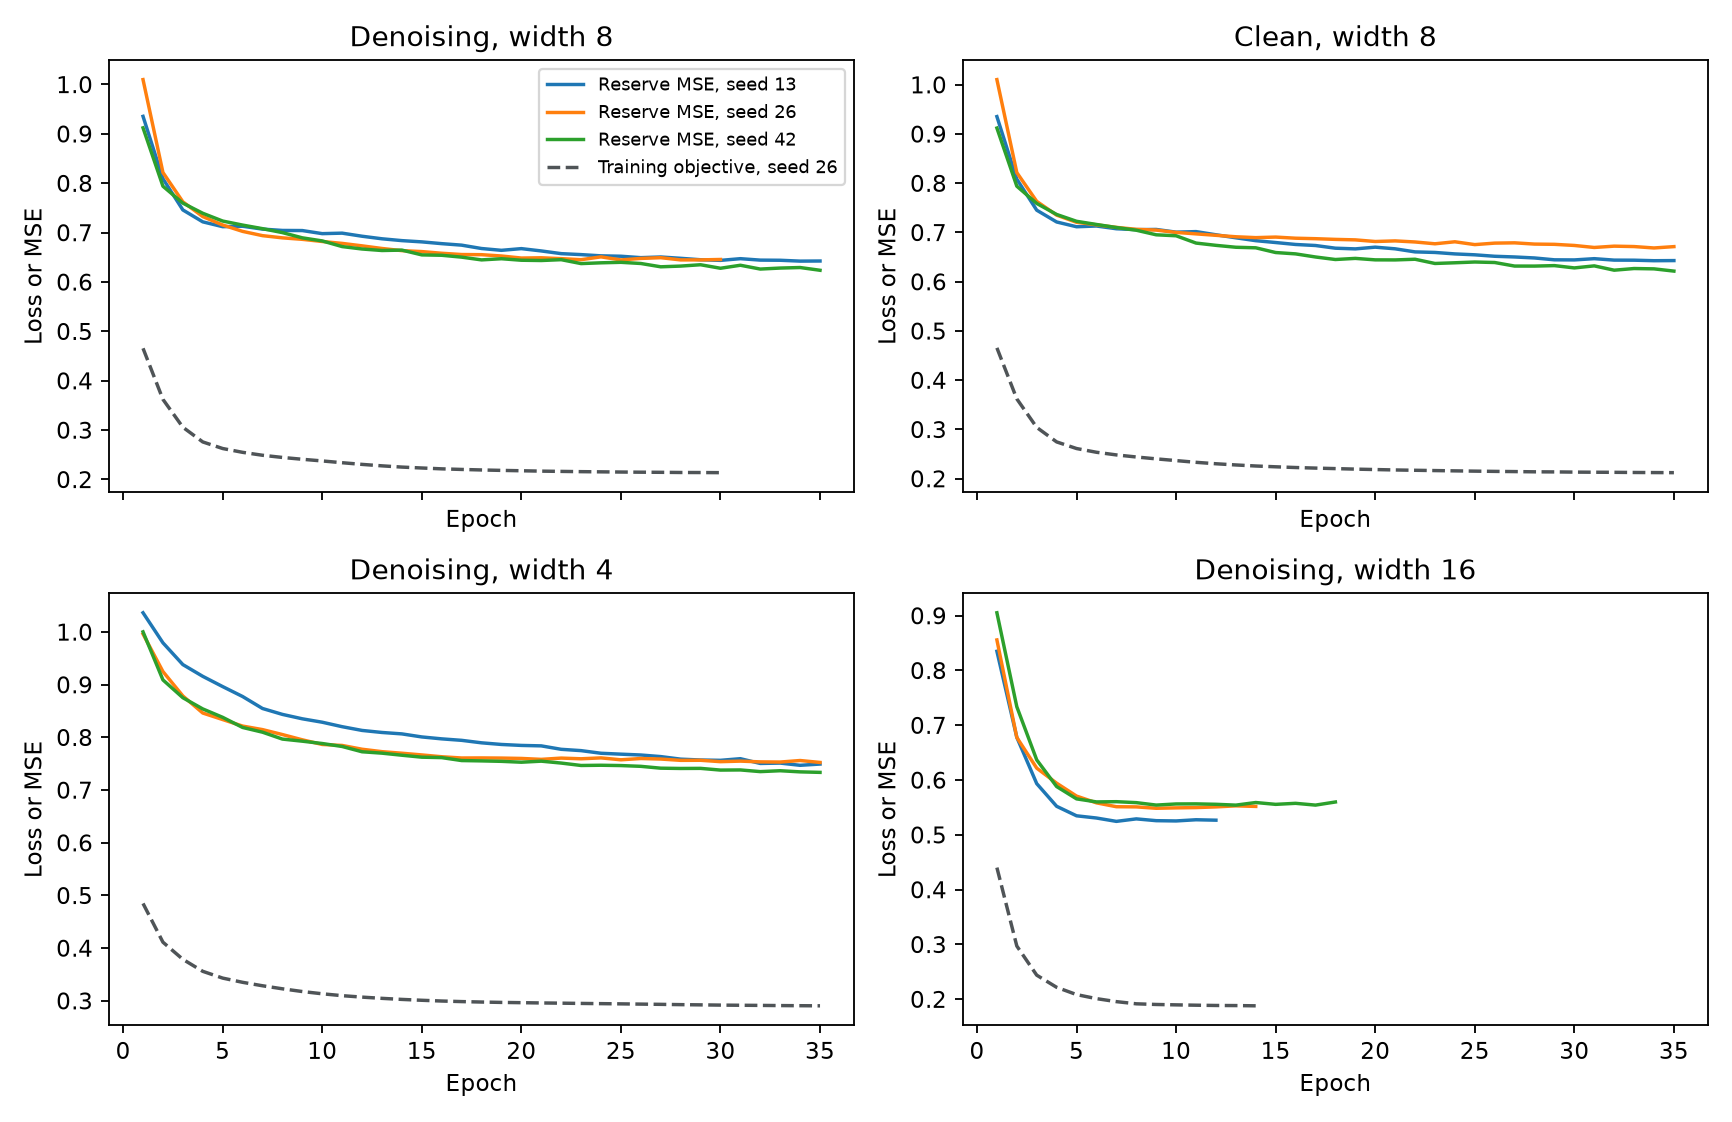

In [5]:
protocol = metadata["ablation"]
print(f"Weight/scaler fitting: {protocol['fit_legitimate_rows']:,} legitimate rows")
print(f"Checkpoint reserve: {protocol['stopping_legitimate_rows']:,} legitimate rows")
print(f"Paired seeds: {', '.join(map(str, protocol['seeds']))}")
display(pd.read_csv(study / "ablation_summary.csv").round(4))
display(pd.read_csv(study / "ablation_trials.csv")
        [["variant", "seed", "epochs", "best_epoch", "best_reserve_mse", "average_precision"]].round(4))
display(Image(filename=str(study / "training_curves.png"), width=940))

At width 8, mean validation AP was 0.0497 with noise and 0.0507 without noise. The difference was small relative to variation across seeds. Width 16 gave the highest mean AP among the tested variants (0.0606). The frozen GMM reached 0.6299 AP on the same mixed validation partition. The curve labeled training objective uses corrupted inputs in the denoising trials and includes the optimizer's loss scaling and penalty. Clean reserve MSE is the checkpoint criterion.

## Reproduction
Run `python run_phase2_study.py --data /path/to/creditcard.csv` from the repository root with the original ULB/Kaggle CSV. The runner verifies the CSV and frozen split, recalculates the historical policies from committed scores, and trains all 12 ablation runs. It records input hashes and environment versions in `results/phase2/study/metadata.json`. This notebook reads the recorded outputs, so it can also run without downloading the CSV.